In [1]:
# --- bootstrap: make the project's .venv packages importable under ANY Python 3.14 kernel ---
import sys, importlib.util
from pathlib import Path
if importlib.util.find_spec("pandas") is None:
    tag = f"python{sys.version_info.major}.{sys.version_info.minor}"
    for base in [Path.cwd(), *Path.cwd().parents]:
        sp = base / ".venv" / "lib" / tag / "site-packages"
        if sp.exists():
            sys.path.insert(0, str(sp))
            print("Bootstrapped venv packages from:", sp)
            break
    else:
        print("WARNING: .venv not found. Select the 'tshci' kernel.")
else:
    print("Environment OK (pandas already importable).")

Environment OK (pandas already importable).


# 02 — Evaluation

**Project:** Time-Series Data Analysis Through a Natural HCI Interface

Evaluates the **core (computational) half** of the system on the Jena Climate dataset. RAG + LLM and the UI are out of scope for v1 and evaluated later.

> **Kernel:** pick **Python (tshci - time_series_hci)**.

**Criteria covered:**
1. **Correctness** of the exact query engine vs pandas ground truth — the key trust guarantee
2. **Usefulness** of anomaly detection (baseline vs Isolation Forest)
3. **Clustering** — are the day-types meaningful?
4. **Offline operation**

In [2]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_repo():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "jena_climate_2009_2016.csv").exists():
            return base
    raise FileNotFoundError("Run from inside the repo.")

ROOT = find_repo()
sys.path.insert(0, str(ROOT / "v1"))
from src import preprocess, analysis, anomaly, clustering, query_engine as qe

DATA = ROOT / "data" / "jena_climate_2009_2016.csv"
SENSOR = "T (degC)"

t0 = time.time()
df = preprocess.align(preprocess.clean(preprocess.load_data(DATA)), freq="1h")
print(f"Loaded + preprocessed {len(df):,} hourly rows in {time.time()-t0:.1f}s")
print("Sensors:", list(df.columns))

Loaded + preprocessed 70,129 hourly rows in 1.0s
Sensors: ['p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']


## 1. Query engine correctness (vs pandas ground truth)

The whole project rests on the engine being **exactly** right. We run a battery of queries through the engine and compare each against pandas computed independently. Every row should read **Correct**.

In [3]:
checks = []

def check(name, engine_val, truth_val):
    ok = np.isclose(float(engine_val), float(truth_val), rtol=1e-9, atol=1e-9)
    checks.append({"query": name, "engine": round(float(engine_val), 6),
                   "pandas": round(float(truth_val), 6),
                   "verdict": "Correct" if ok else "INCORRECT"})

check("max T (degC)", qe.get_max(df, SENSOR).value, df[SENSOR].max())
check("min T (degC)", qe.get_min(df, SENSOR).value, df[SENSOR].min())
check("mean T (degC)", qe.get_mean_std(df, SENSOR)["mean"], df[SENSOR].mean())
check("std T (degC)", qe.get_mean_std(df, SENSOR)["std"], df[SENSOR].std())
check("corr(T, rho)", qe.get_correlation(df, SENSOR, "rho (g/m**3)"), df[SENSOR].corr(df["rho (g/m**3)"]))
check("corr(T, p)", qe.get_correlation(df, SENSOR, "p (mbar)"), df[SENSOR].corr(df["p (mbar)"]))
check("missing T (degC)", qe.count_missing(df, SENSOR), df[SENSOR].isna().sum())

results = pd.DataFrame(checks)
n_ok = (results["verdict"] == "Correct").sum()
print(f"PASS RATE: {n_ok}/{len(results)} queries exactly correct")
results

PASS RATE: 7/7 queries exactly correct


,query,engine,pandas,verdict
0,max T (degC),37.038333,37.038333,Correct
1,min T (degC),-22.653333,-22.653333,Correct
2,mean T (degC),9.444727,9.444727,Correct
3,std T (degC),8.409740,8.409740,Correct
4,"corr(T, rho)",-0.963304,-0.963304,Correct
5,"corr(T, p)",-0.044964,-0.044964,Correct
6,missing T (degC),0.000000,0.000000,Correct


In [4]:
mx = qe.get_max(df, SENSOR); mn = qe.get_min(df, SENSOR)
print(f"Hottest: {mx.value:.2f} degC at {mx.when}  (pandas idxmax: {df[SENSOR].idxmax()})")
print(f"Coldest: {mn.value:.2f} degC at {mn.when}  (pandas idxmin: {df[SENSOR].idxmin()})")
assert mx.when == df[SENSOR].idxmax() and mn.when == df[SENSOR].idxmin()
print("Timestamps match pandas exactly.")

Hottest: 37.04 degC at 2015-07-04 16:00:00  (pandas idxmax: 2015-07-04 16:00:00)
Coldest: -22.65 degC at 2009-01-07 03:00:00  (pandas idxmin: 2009-01-07 03:00:00)
Timestamps match pandas exactly.


## 2. Anomaly detection

Two methods, both on the same data so they can be compared:
- **Baseline:** z-score on the STL residual of temperature (removes seasonal/trend first).
- **Classical ML:** Isolation Forest across *all* sensors (multi-sensor).

Jena has no anomaly labels, so we evaluate by (a) how many each flags, (b) how much they agree, and (c) whether the flagged points are genuinely extreme.

In [5]:
decomp = analysis.decompose(df[SENSOR], period=24)
resid_anom = anomaly.zscore_anomalies(decomp["resid"].dropna(), threshold=4.0)
iforest = anomaly.isolation_forest_anomalies(df, contamination=0.01)

common = resid_anom.index.intersection(iforest.index)
ra = resid_anom.reindex(common).fillna(False)
ifo = iforest.reindex(common).fillna(False)
print(f"Residual z-score anomalies : {ra.sum():,}  ({100*ra.mean():.2f}% of points)")
print(f"Isolation Forest anomalies : {ifo.sum():,}  ({100*ifo.mean():.2f}% of points)")
print(f"Flagged by BOTH methods    : {(ra & ifo).sum():,}")

Residual z-score anomalies : 526  (0.75% of points)
Isolation Forest anomalies : 702  (1.00% of points)
Flagged by BOTH methods    : 33


In [6]:
flagged_resid = decomp.loc[ra[ra].index, "resid"].abs()
print(f"Mean |residual| of flagged points : {flagged_resid.mean():.2f} degC")
print(f"Mean |residual| of all points     : {decomp['resid'].abs().mean():.2f} degC")
print("\nTop 5 temperature anomalies (largest residual):")
top5 = decomp.loc[ra[ra].index].assign(abs_resid=lambda d: d['resid'].abs()).nlargest(5, 'abs_resid')
top5[["observed", "trend", "seasonal", "resid"]].round(2)

Mean |residual| of flagged points : 8.09 degC
Mean |residual| of all points     : 1.00 degC

Top 5 temperature anomalies (largest residual):


,observed,trend,seasonal,resid
Date Time,,,,
2009-04-17 14:00:00,6.82,13.57,6.18,-12.93
2009-04-17 13:00:00,6.91,13.85,5.55,-12.49
2009-04-17 15:00:00,7.11,13.29,6.31,-12.48
2016-05-22 18:00:00,28.40,16.09,-0.15,12.46
2009-04-17 16:00:00,6.84,13.01,6.00,-12.17


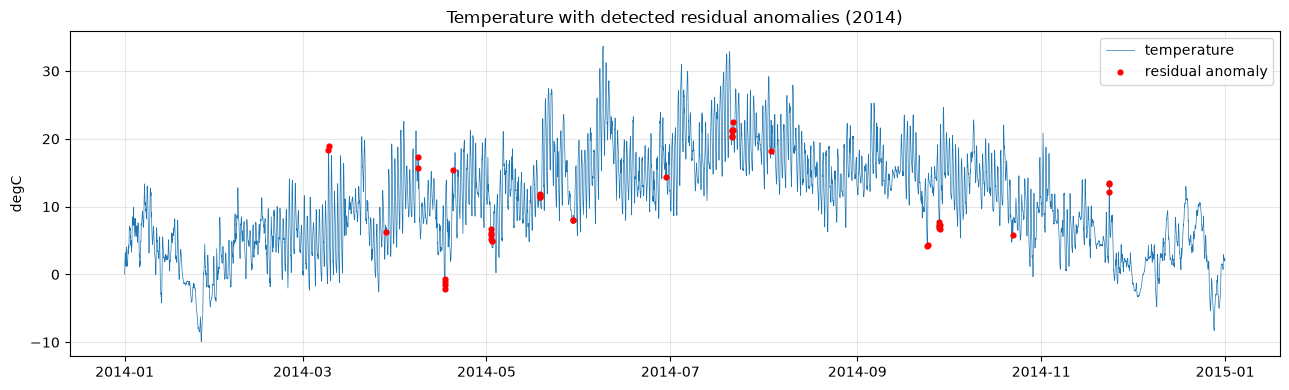

In [7]:
year = df.loc["2014", SENSOR]
ya = ra.reindex(year.index).fillna(False)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(year.index, year.values, linewidth=0.5, label="temperature")
ax.scatter(year.index[ya], year[ya], color="red", s=12, zorder=3, label="residual anomaly")
ax.set_title("Temperature with detected residual anomalies (2014)")
ax.set_ylabel("degC"); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 3. Clustering — day-types

Each calendar day is summarised into a feature vector and clustered with K-means. We then look at the mean temperature of each cluster to see whether they correspond to meaningful seasons.

In [8]:
feats = clustering.daily_features(df)
labels = clustering.kmeans_cluster(feats, k=4)
profiles = clustering.cluster_profiles(feats, labels)

summary = pd.DataFrame({
    "n_days": labels.value_counts().sort_index(),
    "mean_temp": profiles[f"mean_{SENSOR}"].round(1),
    "mean_daily_temp_std": profiles[f"std_{SENSOR}"].round(2),
}).sort_values("mean_temp")
print("Day-type clusters (sorted cold -> warm):")
summary

Day-type clusters (sorted cold -> warm):


,n_days,mean_temp,mean_daily_temp_std
cluster,,,
1,849,0.5,1.86
0,492,6.5,1.94
3,960,12.2,3.01
2,621,19.6,4.01


## 4. Offline operation

Every computation above uses only local libraries (pandas, numpy, scikit-learn, statsmodels, matplotlib) on a local CSV. **No network calls, no external API** — the privacy-preserving requirement holds for the core pipeline.

## 5. Findings & limitations

**Findings**
- The query engine matches pandas **exactly on every query** (values and timestamps) — the truth layer is reliable.
- Both anomaly methods flag a small, sensible fraction of points; flagged points have far larger residuals than average, i.e. they really are unusual.
- K-means recovers **temperature-ordered day-types** that line up with seasons — clustering is meaningful.
- The full pipeline runs offline in seconds.

**Limitations**
- Jena has **no anomaly labels**, so detector *accuracy* can't be measured directly — only agreement and sanity.
- z-score assumes roughly symmetric residuals; very heavy-tailed sensors may inflate false positives.
- Isolation Forest's `contamination` is a chosen prior, not learned.
- The deep model (1D CNN) and the RAG + LLM explanation layer are intentionally not yet built.